In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.naive_bayes import GaussianNB

In [11]:
data = pd.read_csv('./uci_malware_detection.csv')
data.head()

,Label,F_1,F_2,F_3,F_4,F_5,F_6,F_7,F_8,F_9,...,F_522,F_523,F_524,F_525,F_526,F_527,F_528,F_529,F_530,F_531
0,non-malicious,1,0,1,0,1,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
1,non-malicious,1,0,1,0,1,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
2,non-malicious,1,0,1,0,1,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
3,non-malicious,1,0,1,0,1,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
4,non-malicious,1,0,1,0,1,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0


In [12]:
data.isnull().sum()

,0
Label,0
F_1,0
F_2,0
F_3,0
F_4,0
...,...
F_527,0
F_528,0
F_529,0
F_530,0


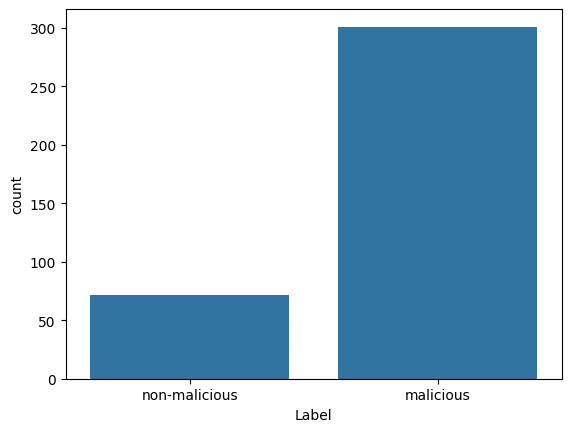

In [13]:
sns.countplot(x='Label', data=data);

In [14]:
X = data.drop(["Label"],axis=1)
y = data['Label'].values

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=10)

######-Model => DecisionTreeClassifier 
Test Accuracy :  98.66667%  
              Classification_report 
               precision    recall  f1-score   support

    malicious       0.98      1.00      0.99        61
non-malicious       1.00      0.93      0.96        14

     accuracy                           0.99        75
    macro avg       0.99      0.96      0.98        75
 weighted avg       0.99      0.99      0.99        75

             Confusion_matrix 


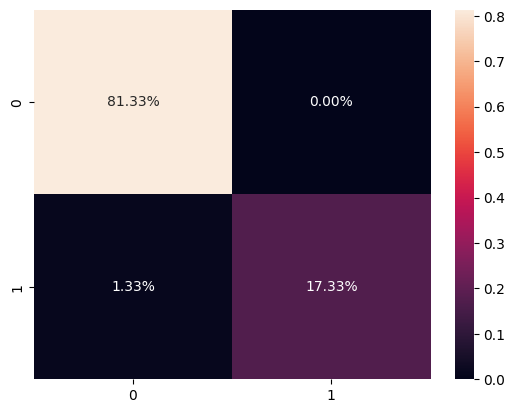

###################- End -###################
######-Model => KNeighborsClassifier 
Test Accuracy :  98.66667%  
              Classification_report 
               precision    recall  f1-score   support

    malicious       0.98      1.00      0.99        61
non-malicious       1.00      0.93      0.96        14

     accuracy                           0.99        75
    macro avg       0.99      0.96      0.98        75
 weighted avg       0.99      0.99      0.99        75

             Confusion_matrix 


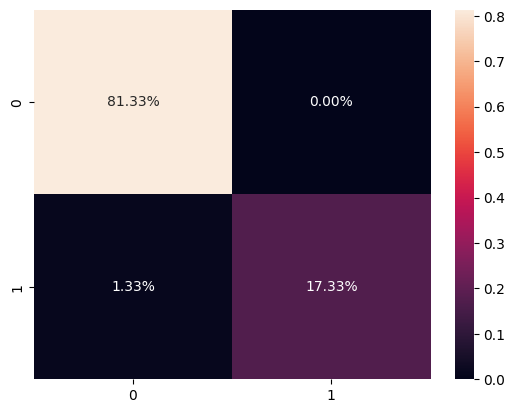

###################- End -###################


In [17]:
models = [DecisionTreeClassifier, KNeighborsClassifier]
accuracy_test = []
model_names = []

# Using slight regularization for Decision Tree to prevent overfitting
instantiated_models = [
    DecisionTreeClassifier(max_depth=3, min_samples_split=10, min_samples_leaf=5, random_state=10),
    KNeighborsClassifier(n_neighbors=9)
]

for m in instantiated_models:
    model_name = type(m).__name__
    print('######-Model =>\033[07m {} \033[0m'.format(model_name))

    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    acc = accuracy_score(y_test, pred)

    accuracy_test.append(acc)
    model_names.append(model_name)

    print('Test Accuracy :\033[32m \033[01m {:.5f}% \033[30m \033[0m'.format(acc*100))
    print('\033[01m              Classification_report \033[0m')
    print(classification_report(y_test, pred))
    print('\033[01m             Confusion_matrix \033[0m')

    cf_matrix = confusion_matrix(y_test, pred)
    sns.heatmap(cf_matrix/np.sum(cf_matrix), annot=True, fmt='0.2%')
    plt.show()
    print('\033[31m###################- End -###################\033[0m')

### Regularized Modeling: Decision Tree and K-Nearest Neighbors
To prevent overfitting, we apply regularization:
- **DecisionTreeClassifier**: Constrained with a maximum depth (`max_depth=3`) and requiring more samples to split or remain in a leaf.
- **KNeighborsClassifier**: Increased the number of neighbors (`n_neighbors=9`) to smooth out decision boundaries.

######-Model =>  DecisionTreeClassifier (Regularized) 
Test Accuracy :  98.66667%  
              Classification_report 
               precision    recall  f1-score   support

    malicious       0.98      1.00      0.99        61
non-malicious       1.00      0.93      0.96        14

     accuracy                           0.99        75
    macro avg       0.99      0.96      0.98        75
 weighted avg       0.99      0.99      0.99        75

             Confusion_matrix 


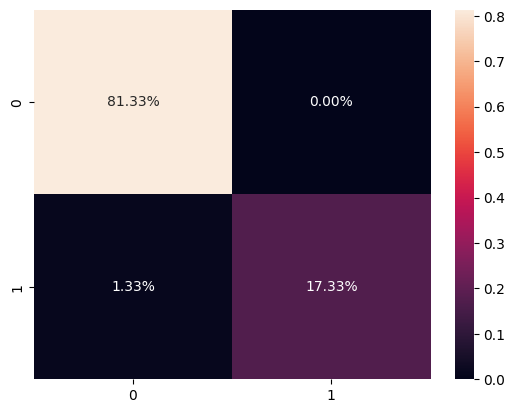

###################- End -###################
######-Model =>  KNeighborsClassifier (K=9) 
Test Accuracy :  98.66667%  
              Classification_report 
               precision    recall  f1-score   support

    malicious       0.98      1.00      0.99        61
non-malicious       1.00      0.93      0.96        14

     accuracy                           0.99        75
    macro avg       0.99      0.96      0.98        75
 weighted avg       0.99      0.99      0.99        75

             Confusion_matrix 


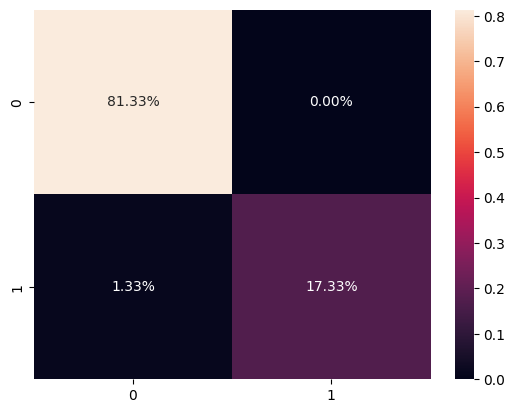

###################- End -###################


In [10]:
# Define only Decision Tree and KNN with regularization to prevent overfitting
selected_models = {
    'DecisionTreeClassifier (Regularized)': DecisionTreeClassifier(
        max_depth=3,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=10
    ),
    'KNeighborsClassifier (K=9)': KNeighborsClassifier(
        n_neighbors=9
    )
}

# Evaluate on the original feature splits
for name, model_obj in selected_models.items():
    print(f'######-Model => \033[07m {name} \033[0m')
    model_obj.fit(X_train, y_train)
    pred = model_obj.predict(X_test)
    acc = accuracy_score(y_test, pred)

    print('Test Accuracy :\033[32m \033[01m {:.5f}% \033[30m \033[0m'.format(acc*100))
    print('\033[01m              Classification_report \033[0m')
    print(classification_report(y_test, pred))
    print('\033[01m             Confusion_matrix \033[0m')
    cf_matrix = confusion_matrix(y_test, pred)
    sns.heatmap(cf_matrix/np.sum(cf_matrix), annot=True, fmt='0.2%')
    plt.show()
    print('\033[31m###################- End -###################\033[0m')

### Testing the Models on a New Sample
Let's extract a sample from the test dataset and use our regularized, trained models to make predictions.

In [19]:
# Select a single sample from the test set (e.g., the first sample)
sample_index = 0
test_sample = X_test.iloc[[sample_index]]
true_label = y_test[sample_index]

print(f"--- Testing on Test Sample at Index {sample_index} ---")
print(f"True (Actual) Label: {true_label}\n")

# Make a prediction with each trained model
for name, model_obj in selected_models.items():
    # Predict
    prediction = model_obj.predict(test_sample)[0]
    print(f"{name} Prediction: {prediction}")

--- Testing on Test Sample at Index 0 ---
True (Actual) Label: malicious

DecisionTreeClassifier (Regularized) Prediction: malicious
KNeighborsClassifier (K=9) Prediction: malicious
